# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

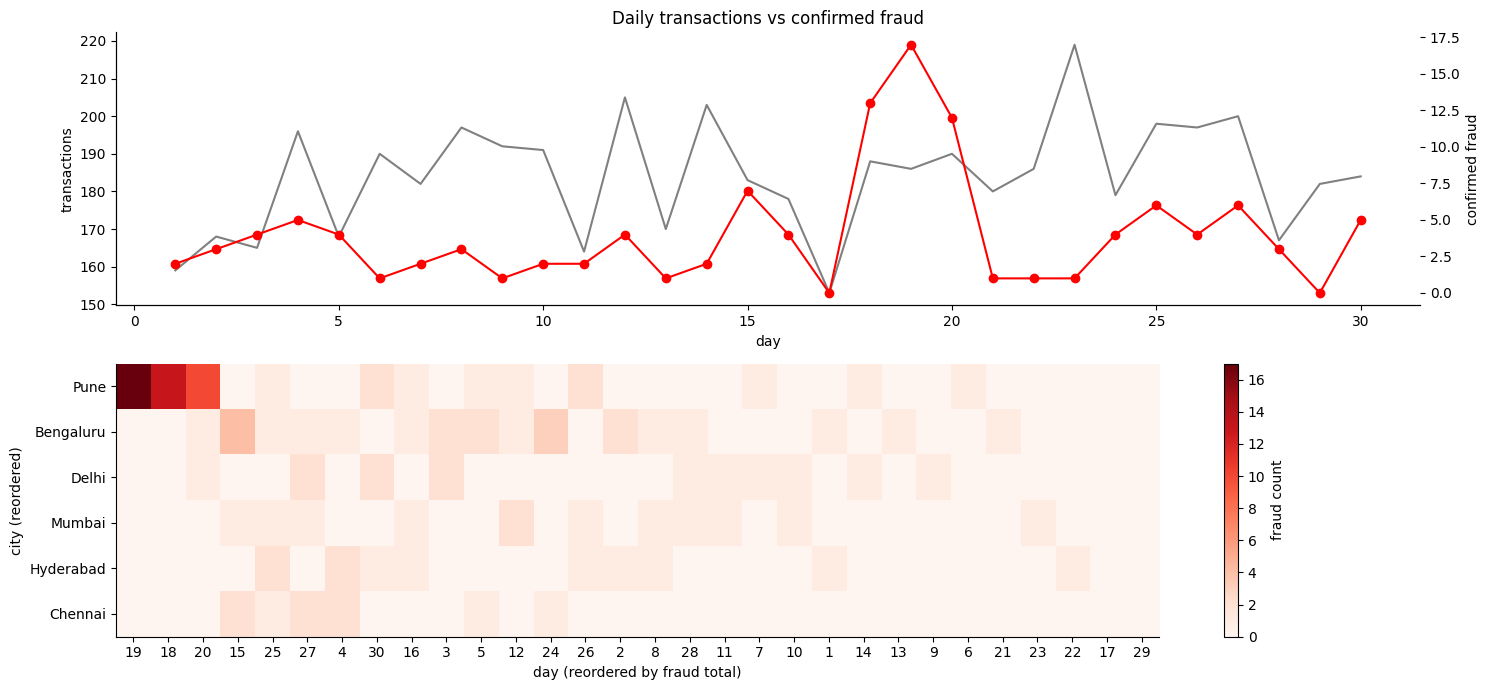

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           5       2
           2       2
           3       2
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: daily volume (left axis) + daily fraud (right axis)
daily = tx.groupby("day").agg(n=("txn_id", "count"), fraud=("is_fraud", "sum"))
ax = axes[0]
ax.plot(daily.index, daily.n, color="grey", label="transactions")
ax.set_xlabel("day"); ax.set_ylabel("transactions")
ax2 = ax.twinx()
ax2.plot(daily.index, daily.fraud, color="red", marker="o", label="confirmed fraud")
ax2.set_ylabel("confirmed fraud")
ax.set_title("Daily transactions vs confirmed fraud")

# TODO 2: city x day matrix, reordered by totals
heat = (tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id",
                                         aggfunc="count", fill_value=0)
          .reindex(columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("day (reordered by fraud total)"); axes[1].set_ylabel("city (reordered)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3: top (city, day) cells
print(tx[tx.is_fraud == 1].groupby(["city", "day"]).size()
        .sort_values(ascending=False).head(8))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_  The overview shows that fraud is concentrated in Pune on days 18–20 (17, 13 and 10 frauds; about 40 of the 120). A list sorted by detector score shows individual transactions and cannot show this cluster in place and time. The concept is reordering the matrix (Slide 39), which makes the block pop out. It also reflects overview-first and pattern discovery (Slide 38).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

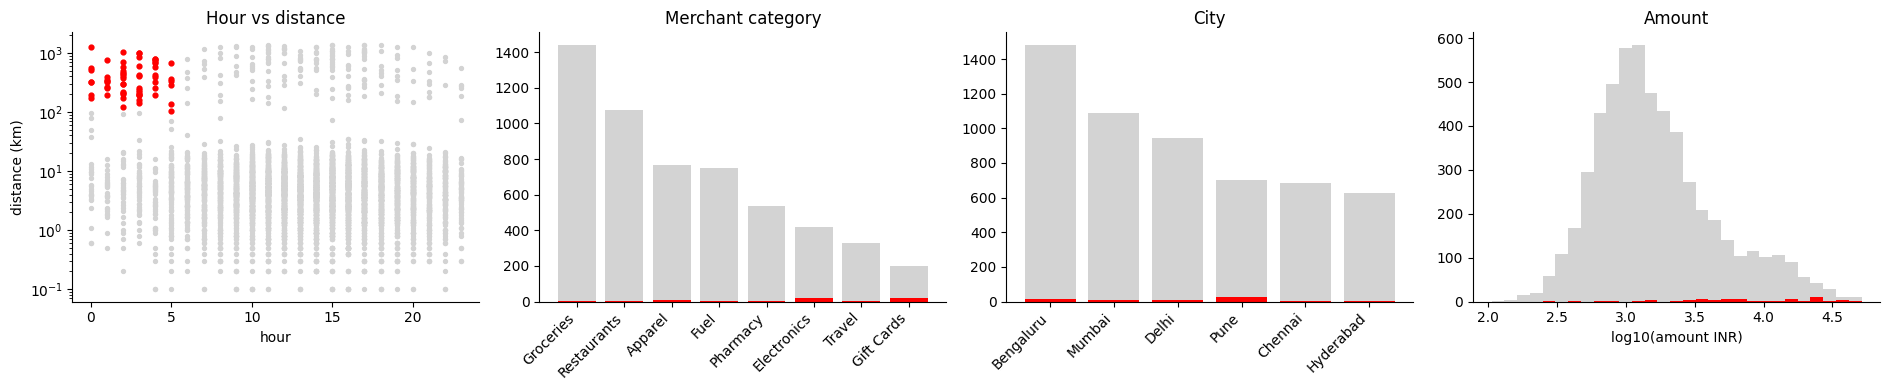

Brushed: 61
Fraud rate in brush: 86.9% vs overall 2.2%
Share of all fraud captured: 44.2%


In [3]:
# TODO 1
brush = (tx.night) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2
# (a) hour vs distance (log y)
axes[0].scatter(tx.hour, tx.distance_from_home_km, c="lightgrey", s=8)
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], c="red", s=12)
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance (km)")
axes[0].set_title("Hour vs distance")

# (b) merchant category counts
cats = tx.merchant_category.value_counts()
x = np.arange(len(cats))
axes[1].bar(x, cats.values, color="lightgrey")
axes[1].bar(x, tx[brush].merchant_category.value_counts().reindex(cats.index, fill_value=0).values, color="red")
axes[1].set_xticks(x); axes[1].set_xticklabels(cats.index, rotation=45, ha="right")
axes[1].set_title("Merchant category")

# (c) city counts
cities = tx.city.value_counts()
x = np.arange(len(cities))
axes[2].bar(x, cities.values, color="lightgrey")
axes[2].bar(x, tx[brush].city.value_counts().reindex(cities.index, fill_value=0).values, color="red")
axes[2].set_xticks(x); axes[2].set_xticklabels(cities.index, rotation=45, ha="right")
axes[2].set_title("City")

# (d) amount histogram (log10)
bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="red")
axes[3].set_xlabel("log10(amount INR)"); axes[3].set_title("Amount")

plt.tight_layout(); plt.show()

# TODO 3
print(f"Brushed: {brush.sum()}")
print(f"Fraud rate in brush: {tx.is_fraud[brush].mean():.1%} vs overall {tx.is_fraud.mean():.1%}")
print(f"Share of all fraud captured: {tx.is_fraud[brush].sum() / tx.is_fraud.sum():.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_  The brush selects 61 transactions with an 86.9% fraud rate, against 2.2% overall. It captures only about 44% of all fraud, so relying on this rule alone would miss more than half of it. The city view (the Pune spike) and the hour-vs-distance scatter, where grey points stay unbrushed, hint that the rest of the fraud is a Pune-concentrated cluster outside the night/far rule.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: best of 5
best_s = min(
    (lambda t0: (big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)], time.perf_counter() - t0)[1])(time.perf_counter())
    for _ in range(5)
)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / best_s * len(big)

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = max(0, 1 - 0.1 / t_50m) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 9.5 ms -> 0.0094 us/row -> max 10,617,412 rows in 0.1 s
50M rows -> 0.47 s; must skip 78.8% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_  Use aggregation or binning (pre-aggregated histograms or a data cube; Slide 5/14) or sampling. The slider then queries a small summary instead of 50M rows. The analyst loses individual-record detail and exactness. Rare events, such as the 2% fraud, may be smoothed out or missed when sampling.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

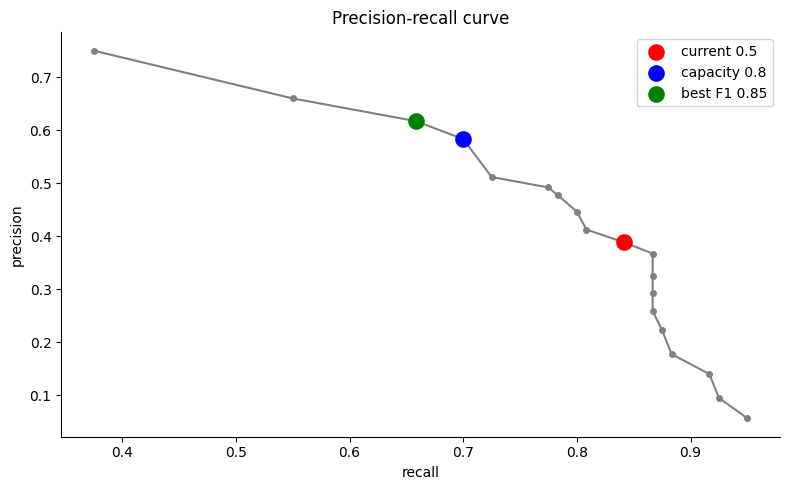

Recommendation: set threshold to 0.8 -> 144.0 alerts, precision 58%, recall 70% (vs 0.5: 260.0 alerts, precision 39%, recall 84%).


In [5]:
rows = []
# TODO 1
for t in np.arange(0.05, 1.0, 0.05):
    flag = tx.detector_score >= t
    tp = (flag & (tx.is_fraud == 1)).sum()
    fp = (flag & (tx.is_fraud == 0)).sum()
    fn = (~flag & (tx.is_fraud == 1)).sum()
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn)
    f1 = 2 * p * r / (p + r) if p + r else 0
    rows.append(dict(threshold=round(t, 2), alerts=flag.sum(), TP=tp, FP=fp, FN=fn,
                     precision=p, recall=r, f1=f1))

pr = pd.DataFrame(rows)

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values("recall", ascending=False).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="grey", markersize=4)
cur = pr[pr.threshold == 0.5].iloc[0]
for row, lab, c in [(cur, "current 0.5", "red"),
                    (capacity_choice, f"capacity {capacity_choice.threshold}", "blue"),
                    (best_f1, f"best F1 {best_f1.threshold}", "green")]:
    ax.scatter(row.recall, row.precision, s=120, color=c, label=lab, zorder=3)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall curve")
ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set threshold to {capacity_choice.threshold} -> {capacity_choice.alerts} alerts, "
      f"precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%} "
      f"(vs 0.5: {cur.alerts} alerts, precision {cur.precision:.0%}, recall {cur.recall:.0%}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_  The Head of Fraud Ops should decide, with the model supplying the trade-off curve. The model optimises a statistical score and does not know about staffing, the cost of a missed fraud, or customer friction from false alerts. Visual analytics keeps a human in the loop (Slides 35–37) because that judgement is domain knowledge the model lacks. The human steers the parameter and checks that the result is sensible.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"confirmed fraud": "red", "legitimate": "lightgrey"},
    hover_data={"txn_id": True, "customer_id": True, "city": True,
                "merchant_category": True, "distance_from_home_km": True,
                "detector_score": True, "label": False},
    title="Flagged transactions (score >= 0.3)")
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
fig2 = px.sunburst(tx, path=["city", "merchant_category"], color="is_fraud",
                   color_continuous_scale="Reds",
                   title="City -> category (colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_  A tooltip shows one point at a time, so getting an overview of 400 cases means hovering 400 times and keeping them all in memory (Slide 23). The city × day heatmap (Task 1) and the linked views (Task 2) fix this by showing all the cases together.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window: 37.4% | outside: 1.5% | p = 1.06e-136
(a) Pune other days: 1.9%
(b) Other cities, days 18-20: 0.4%


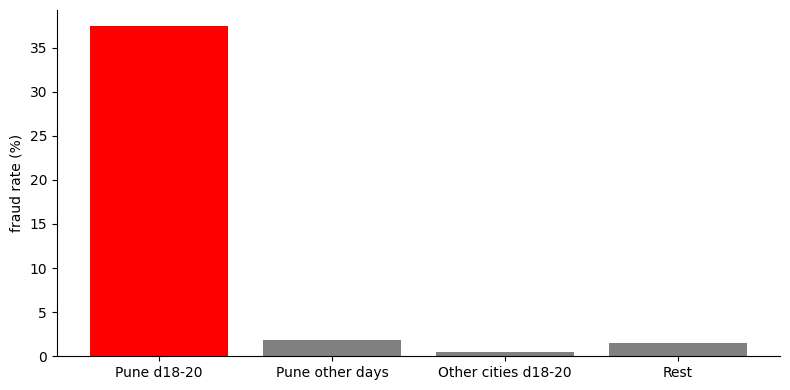

Verdict: localized Pune burst on days 18-20 is SUPPORTED (p=1.06e-136); escalate this window, not all of Pune.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: H: fraud is abnormally high in Pune on days 18-20
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
chi2, p, _, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"Inside window: {tx.is_fraud[in_window].mean():.1%} | outside: {tx.is_fraud[~in_window].mean():.1%} | p = {p:.2e}")

# TODO 3: counter-examples
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = ~in_window & ~same_city_other_days & ~other_cities_same_days
print(f"(a) Pune other days: {tx.is_fraud[same_city_other_days].mean():.1%}")
print(f"(b) Other cities, days 18-20: {tx.is_fraud[other_cities_same_days].mean():.1%}")

# TODO 4
groups = {"Pune d18-20": in_window, "Pune other days": same_city_other_days,
          "Other cities d18-20": other_cities_same_days, "Rest": rest}
rates = [tx.is_fraud[m].mean() * 100 for m in groups.values()]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(groups.keys(), rates, color=["red", "grey", "grey", "grey"])
ax.set_ylabel("fraud rate (%)")

plt.tight_layout(); plt.show()

# TODO 5
verdict = "SUPPORTED" if (p < 0.01 and rates[0] > 3 * max(rates[1:3])) else "NOT SUPPORTED"
print(f"Verdict: localized Pune burst on days 18-20 is {verdict} (p={p:.2e}); "
      f"escalate this window, not all of Pune.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_  (a) Pune on other days. If fraud were equally high there, the cause would be a persistent Pune problem (a compromised terminal or a chronic weakness), not an event in a time window.
(b) Other cities on days 18–20. If those were also elevated, it would point to a system-wide spike on those days (a detector or data issue), not a Pune-specific ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_  Last month 120 of 5,520 transactions (2.2%) were confirmed fraud, and about 40 of them were concentrated in Pune on days 18–20. I recommend moving the threshold from 0.5 to 0.80. That gives 144 alerts, within the 150-alert capacity, at 58% precision and 70% recall, whereas 0.5 produces 260 alerts the team cannot review. The best-F1 threshold (0.85) is close, but the Head of Fraud Ops should make the final call, because the model cannot weigh missed fraud against reviewer workload (human in the loop). Build the city × day overview heatmap with linked brushing first, since overview-first plus brushing exposed the Pune burst that the night/far rule alone (44% of fraud) and score-sorted alerts would have hidden. Finally, add the feedback loop (Slide 51): investigators’ confirmed and rejected labels should flow back into retraining, and into threshold tuning, so next month’s detector improves.